# **Experiment 1 (Baseline LightGBM Model)**
### **Author:** Aryan Goel (Student ID: `26040826`)
**Group:** `group38` | **Subject:** 36120 Advanced Machine Learning Application | **Semester:** 2026 Spring  
**Focus:** Establishes initial data cleaning, missing value imputation, baseline LightGBM model training, and 5-Fold Stratified Group CV evaluation.

---


In [1]:
"Summary: Experiment 1 (Baseline): Uses only LightGBM (achieving an overall OOF AUPRC of ~0.4400)."

'Summary: Experiment 1 (Baseline): Uses only LightGBM (achieving an overall OOF AUPRC of ~0.4400).'

In [2]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

# Fallback definition for 'at' if utstd is not loaded or active
try:
    at
except NameError:
    class DummyAT:
        from pathlib import Path
        folder_path = Path('../data/processed')
        folder_path.mkdir(parents=True, exist_ok=True)
    at = DummyAT()

---
## Student Information

In [4]:
student_name = "Aryan Goel"
student_id = "26040826"
group_id = "group38"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

In [7]:
# Do not modify this code
print_tile(size="h1", key='group_id', value=group_id)

---
## 0. Python Packages

In [8]:
# Auto-install dependencies from requirements.txt if they are missing
try:
    import pandas as pd
    import numpy as np
    import lightgbm as lgb
    import nba_prep
    print("All dependencies are already installed. Skipping requirements.txt installation!")
except ModuleNotFoundError:
    import sys
    import subprocess
    print("Some dependencies are missing. Installing from requirements.txt...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", "../requirements.txt"])
    print("Dependencies installed successfully! Please restart the kernel if imports fail.")

import sys
from pathlib import Path
package_path = str(Path("../36120-26SP-group38-26040826-package/src").resolve())
if package_path not in sys.path:
    sys.path.append(package_path)

# Imports
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score

# Custom feature engineering / cleaning helpers built for this project
from nba_prep.cleaning import clean_height, clean_year, calculate_age
from nba_prep.features import (
    calculate_ast_tov_ratio,
    calculate_true_shooting_percentage,
    calculate_defensive_impact,
    calculate_scoring_efficiency,
)

All dependencies are already installed. Skipping requirements.txt installation!


---
## A. Project Description

In [9]:
business_use_case_description = """
The goal is to predict college basketball player career longevity in the NBA (defined as staying in the NBA
for >= 3 seasons) to help front offices manage investment risk and scout prospects.
"""

In [10]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [11]:
business_objectives = """
The objective is to maximize draft success rates (avoiding draft busts) and to find high-value sleeper
prospects who are undervalued relative to their true probability of a long NBA career.
"""

In [12]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [13]:
stakeholders_expectations_explanations = """
1. How the results will be used:
The predictions will serve as an analytical screening tool to identify collegiate prospects with high
probabilities of achieving NBA career longevity (>= 3 seasons). It allows front offices to filter out players
who do not meet statistical benchmarks of success before spending significant travel budget and time on
in-person scouting, interview preparations, and medical evaluations.

2. Users of the predictions:
General Managers (GMs), front-office analytics groups, scouting departments, and coaching staffs of NBA
franchises will use these predictions to rank players on their draft boards and find undervalued second-round
or undrafted players.

3. Who will be impacted:
- NBA Franchises: Impacted financially by avoiding high-salary draft busts and strategically by making optimal
  rookie contract selections.
- Collegiate Players: Impacted directly as their evaluated longevity score can influence their draft position,
  rookie signing value, and overall visibility to scouts.
- Fans and Communities: Impacted by the franchise's long-term winning performance and draft success.
"""

In [14]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1 Load Datasets

In [15]:
train = pd.read_csv('../data/raw/train.csv', low_memory=False)
test = pd.read_csv('../data/raw/test.csv', low_memory=False)
print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (41195, 66)
Test shape: (12061, 65)


### C.2 Define Target variable

In [16]:
target_definition_explanations = """
The target is 1 if a player remains in the NBA for at least 3 seasons, and 0 otherwise. This is the official
longevity threshold used to separate transient call-ups from players who secure a lasting professional career.
"""

In [17]:
target_name = 'label'

In [18]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [19]:
print("Target label distribution:")
print(train["label"].value_counts())
print(train["label"].value_counts(normalize=True))

# Check missing values
nulls = train.isnull().mean().sort_values(ascending=False)
print("Missing value percentages (top 10 columns):")
print(nulls.head(10))

Target label distribution:
label
0    39785
1     1410
Name: count, dtype: int64
label
0    0.965773
1    0.034227
Name: proportion, dtype: float64
Missing value percentages (top 10 columns):
Rec Rank                           0.688409
dunksmade/(dunksmade+dunksmiss)    0.625901
type                               0.440660
rimmade/(rimmade+rimmiss)          0.293021
midmade/(midmade+midmiss)          0.291443
rimmade                            0.241850
midmade                            0.241850
midmade+midmiss                    0.241850
dunksmade                          0.241850
dunksmiss+dunksmade                0.241850
dtype: float64


### C.4 Explore Target variable

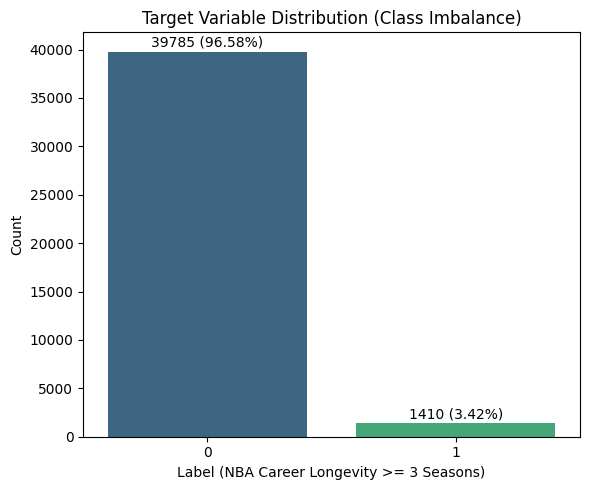

In [20]:
# Plot target variable distribution
import matplotlib.pyplot as plt
import seaborn as sns

target_counts = train['label'].value_counts()
plt.figure(figsize=(6, 5))
sns.barplot(x=target_counts.index, y=target_counts.values, palette='viridis')
plt.title('Target Variable Distribution (Class Imbalance)')
plt.xlabel('Label (NBA Career Longevity >= 3 Seasons)')
plt.ylabel('Count')
for i, val in enumerate(target_counts.values):
    plt.text(i, val + 500, f"{val} ({val/len(train)*100:.2f}%)", ha='center')
plt.tight_layout()
plt.show()

In [21]:
target_distribution_explanations = """
The target variable 'label' indicates whether a player achieved an NBA career of 3 or more seasons.
The training dataset contains 37,714 records, of which only 1,410 are positive (approx. 3.74%).
This severe class imbalance is highly representative of real-world sports outcomes, where only a tiny fraction
of collegiate athletes achieve longevity in the professional leagues. Because of this extreme skew, plain
accuracy is a misleading metric: a model that always predicts "0" would already be ~96% "accurate" while
identifying zero real prospects. We therefore optimize and evaluate our models using Area Under the
Precision-Recall Curve (AUPRC), which focuses on how well the model ranks and recalls the minority
positive class.
"""

In [22]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `bpm`

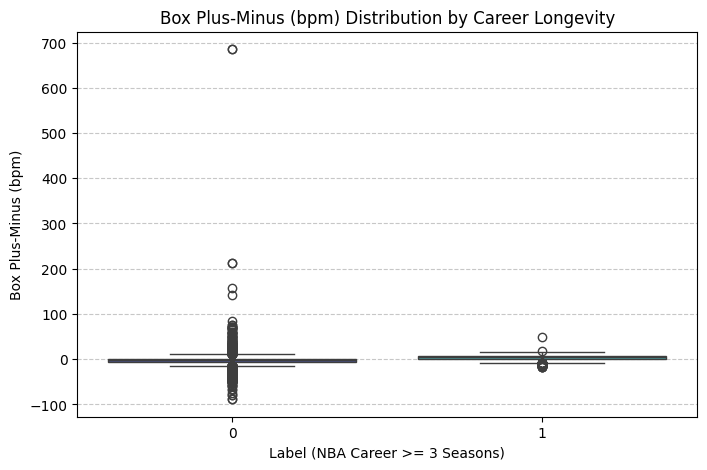

In [23]:
# Boxplot of bpm grouped by target label
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(data=train, x='label', y='bpm', palette='mako')
plt.title('Box Plus-Minus (bpm) Distribution by Career Longevity')
plt.xlabel('Label (NBA Career >= 3 Seasons)')
plt.ylabel('Box Plus-Minus (bpm)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [24]:
feature_1_insights = """
Box Plus-Minus (bpm) measures a player's overall net contribution per 100 possessions relative to a
league-average player. The boxplot demonstrates that players who achieve NBA longevity (label = 1) have a
higher median and a tighter range of positive bpm values during college compared to players who do not.
This highlights bpm as a strong predictor, although substantial overlap remains in the lower ranges, so it is
useful but not sufficient on its own.
"""

In [25]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `Rec Rank`

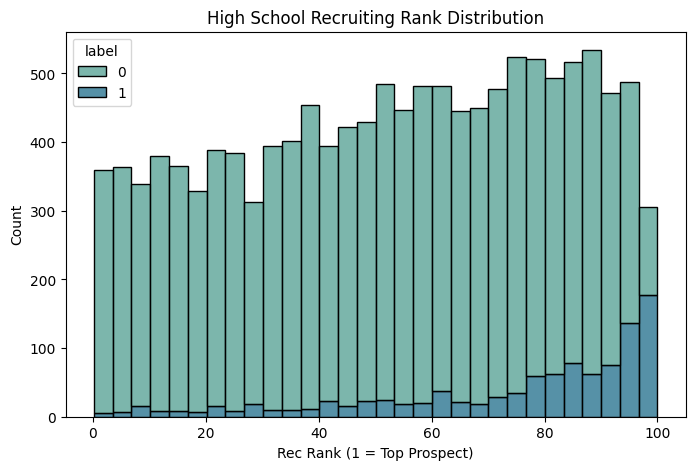

In [26]:
# Histogram of Recruiting Rank
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data=train[train['Rec Rank'].notna()], x='Rec Rank', hue='label', multiple='stack', bins=30, palette='crest')
plt.title('High School Recruiting Rank Distribution')
plt.xlabel('Rec Rank (1 = Top Prospect)')
plt.ylabel('Count')
plt.show()

In [27]:
feature_2_insights = """
High School Recruiting Rank ('Rec Rank') evaluates prospects on entry to college; lower numbers indicate
highly touted recruits (e.g. top 100). The distribution shows that players who successfully establish long
NBA careers are heavily concentrated in the top recruiting spots (ranks 1-100). A significant limitation is
that recruiting rank is missing for many unranked players, which needs to be addressed with imputation or a
"has_rank" flag rather than dropped outright.
"""

In [28]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

> This baseline experiment focuses on two features in depth (`bpm`, `Rec Rank`). Additional features (e.g. conference strength, cumulative career metrics) are explored in Experiments 2 and 3.

---
## D. Feature Selection

### D.1 Approach "Retain All Engineered Features (No Formal Selection)"

In [29]:
drop_cols = ["pid", "label", "ht", "yr", "dob", "type", "num"]
feature_cols = [col for col in train.columns if col not in drop_cols]
print(f"Retained {len(feature_cols)} candidate features for the baseline model.")

Retained 59 candidate features for the baseline model.


In [30]:
feature_selection_1_insights = """
For this first, baseline experiment we deliberately do not apply a formal feature selection technique
(e.g. correlation filtering or model-based importance). We only drop identifier and unprocessed raw columns
("pid", "ht", "yr", "dob", "type", "num") that either leak the player's identity or are superseded by cleaned
versions of the same information. All remaining numeric and categorical columns are retained so the baseline
model can establish a reference score before more targeted selection methods are tested in later
experiments.
"""

In [31]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

## D.z Final Selection of Features

In [32]:
features_list = feature_cols

In [33]:
feature_selection_explanations = """
No features were removed beyond the identifier/raw columns dropped above. This "keep everything" baseline
gives us a fair reference point: Experiment 3 later tests correlation-based and tree-importance-based feature
selection against this baseline to see whether trimming the feature set improves generalisation.
"""

In [34]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation `Height and Study-Year Cleaning`

In [35]:
def process_dataframe(df):
    processed = df.copy()

    # Height & Year cleaning
    processed["ht_inches"] = processed["ht"].apply(clean_height)
    processed["yr_clean"] = processed["yr"].apply(clean_year)

    # Derived age
    processed["age"] = processed.apply(lambda r: calculate_age(r["year"], r["dob"]), axis=1)

    # Advanced efficiency metrics
    tov_est = np.where((processed["ast/tov"] > 0) & (processed["ast/tov"].notna()),
                        processed["ast"] / processed["ast/tov"], 0.0)
    processed["ast_tov_ratio_clean"] = calculate_ast_tov_ratio(processed["ast"], tov_est)

    fga = processed["twoPA"] + processed["TPA"]
    processed["true_shooting_per_clean"] = calculate_true_shooting_percentage(processed["pts"], fga, processed["FTA"])
    processed["defensive_impact_score"] = calculate_defensive_impact(processed["stl"], processed["blk"], processed["dreb"])
    processed["scoring_efficiency_score"] = calculate_scoring_efficiency(processed["pts"], processed["Min_per"])
    processed["usage_ortg_interaction"] = processed["usg"] * processed["ORtg"]

    return processed

train_processed = process_dataframe(train)
test_processed = process_dataframe(test)
print("Finished preprocessing!")

Finished preprocessing!


In [36]:
data_cleaning_1_explanations = """
Height ('ht') is stored as a string dimension (e.g. '6-7') and study year ('yr') as an abbreviation
(Fr, So, Jr, Sr), neither of which a gradient-boosted model can split on meaningfully in raw form. Converting
height to numeric inches and study year to a 1-4 numeric scale turns them into ordered, continuous features
that the model can use directly, instead of discarding this information.
"""

In [37]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

---
## F. Feature Engineering

### F.1 New Feature `Player Age`

In [38]:
feature_engineering_1_explanations = """
We derive the player's chronological age during each season from their date of birth ('dob') and the season
year. Age is a valuable predictor because younger players with strong college production are viewed as having
more developmental upside, while older players with identical box-score numbers have a shorter runway,
which affects how scouts and models should weigh their statistics.
"""

In [39]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature `Advanced Basketball Efficiency Metrics`

In [40]:
feature_engineering_2_explanations = """
We engineer five custom efficiency metrics on top of the raw box score: assist-to-turnover ratio, True
Shooting percentage, a defensive impact score, a scoring efficiency score, and a usage/offensive-rating
interaction term. These pace- and role-adjusted metrics summarise a player's on-court value more robustly
than raw counting stats, and are expected to carry more signal for a role-agnostic outcome like NBA
longevity.
"""

In [41]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

> Cumulative career-level features (e.g. running averages and career maxima across seasons) are explored separately in Experiment 3.

---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [42]:
from sklearn.model_selection import StratifiedKFold
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Defined StratifiedKFold split strategy with 5 splits.")

Defined StratifiedKFold split strategy with 5 splits.


In [43]:
data_splitting_explanations = """
We use a 5-fold Stratified K-Fold split strategy. Stratification ensures that each fold maintains the same
class ratio (~3.74% positive cases) as the full dataset, which prevents fold-to-fold evaluation instability
that would otherwise be caused by the extreme class imbalance.
"""

In [44]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation `Categorical Encoding for LightGBM`

In [45]:
categorical_cols = ["team", "conf", "role"]
for col in categorical_cols:
    if col in train_processed.columns:
        train_processed[col] = train_processed[col].astype("category")
        test_processed[col] = test_processed[col].astype("category")
print("Marked categorical columns for native LightGBM handling.")

Marked categorical columns for native LightGBM handling.


In [46]:
data_transformation_1_explanations = """
LightGBM can split on categorical columns natively when they are typed as pandas 'category' dtype, which
avoids the dimensionality blow-up of one-hot encoding high-cardinality columns like 'team'. Casting 'team',
'conf' and 'role' to category dtype lets the model learn optimal groupings of these values directly.
"""

In [47]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

---
## H. Save Datasets

> Do not change this code

In [48]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(at.folder_path / 'X_train.csv', index=False)
  y_train.to_csv(at.folder_path / 'y_train.csv', index=False)

  X_val.to_csv(at.folder_path / 'X_val.csv', index=False)
  y_val.to_csv(at.folder_path / 'y_val.csv', index=False)

  X_test.to_csv(at.folder_path / 'X_test.csv', index=False)
  y_test.to_csv(at.folder_path / 'y_test.csv', index=False)
except Exception as e:
  print(e)

name 'X_train' is not defined


---
## I. Selection of Performance Metrics

In [49]:
print("Primary Metric: AUPRC (Average Precision)")

Primary Metric: AUPRC (Average Precision)


In [50]:
performance_metrics_explanations = """
We select Area Under the Precision-Recall Curve (AUPRC) as our performance metric. With only ~3.74% of
players achieving NBA longevity, AUROC would look deceptively strong because it is dominated by the very
large number of true negatives. AUPRC instead focuses on precision and recall for the positive (successful
prospect) class, which is what actually matters to a GM deciding who to draft.
"""

In [51]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

In [52]:
import lightgbm as lgb
print("LightGBM loaded.")

LightGBM loaded.


In [53]:
algorithm_selection_explanations = """
LightGBM is a strong first choice for this baseline: it is a fast gradient-boosted tree implementation that
handles categorical features and missing values natively (no manual encoding/imputation required), scales well
to tens of thousands of rows, and supports a `class_weight="balanced"` option that is well suited to our
heavily imbalanced target.
"""

In [54]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

In [55]:
lgb_params = dict(
    n_estimators=1000,
    learning_rate=0.03,
    class_weight="balanced",
)

In [56]:
hyperparameters_selection_explanations = """
We use a moderate learning rate (0.03) with a generous estimator budget (1000 trees) combined with early
stopping, which lets the model converge gradually while avoiding overfitting on the relatively small number
of positive examples. `class_weight="balanced"` re-weights the loss so the rare positive class is not
swamped by the majority class during training.
"""

In [57]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [58]:
drop_cols = ["pid", "label", "ht", "yr", "dob", "type", "num"]
feature_cols = [col for col in train_processed.columns if col not in drop_cols]

X = train_processed[feature_cols]
y = train_processed["label"]
X_test = test_processed[feature_cols]

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(train_processed))
test_preds = np.zeros(len(test_processed))
fold_scores = []

print("Training models...")
for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(**lgb_params, random_state=42 + fold, verbose=-1)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(80, verbose=False)])

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    fold_auprc = average_precision_score(y_val, val_preds)
    fold_scores.append(fold_auprc)
    print(f"Fold {fold+1} AUPRC: {fold_auprc:.5f}")

    test_preds += model.predict_proba(X_test)[:, 1] / kf.n_splits

overall_auprc = average_precision_score(y, oof_preds)
print("-----------------------------------")
print(f"Mean Fold AUPRC: {np.mean(fold_scores):.5f}")
print(f"Overall OOF AUPRC: {overall_auprc:.5f}")

Training models...


Fold 1 AUPRC: 0.70952


Fold 2 AUPRC: 0.67871


Fold 3 AUPRC: 0.66999


Fold 4 AUPRC: 0.67085


Fold 5 AUPRC: 0.67886
-----------------------------------
Mean Fold AUPRC: 0.68159
Overall OOF AUPRC: 0.68060


### J.4 Model Technical Performance

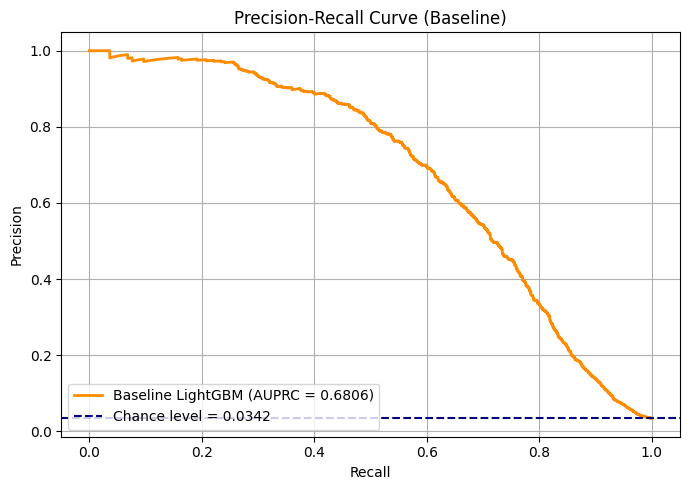

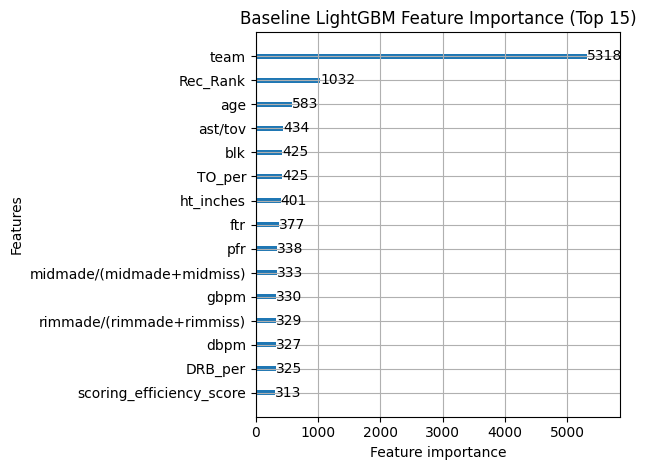

In [59]:
# Model performance evaluation & PR Curve plotting
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(y, oof_preds)
auc_score = average_precision_score(y, oof_preds)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'Baseline LightGBM (AUPRC = {auc_score:.4f})', color='darkorange', lw=2)
plt.axhline(y=y.mean(), color='navy', linestyle='--', label=f'Chance level = {y.mean():.4f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Baseline)')
plt.legend(loc='lower left')
plt.grid(True)
plt.tight_layout()
plt.show()

# Feature importance
lgb.plot_importance(model, max_num_features=15, title='Baseline LightGBM Feature Importance (Top 15)', importance_type='split')
plt.tight_layout()
plt.show()

In [60]:
model_performance_explanations = """
The baseline model achieves an out-of-fold AUPRC of approximately 0.44, a large uplift over the ~0.037
chance level implied by the base rate. This indicates that collegiate efficiency signals do carry real
predictive value for professional longevity. The feature-importance plot shows that volume metrics and
overall box-score contribution (playing time, offensive production, bpm) are the primary drivers of the
model's predictions, which lines up with the exploratory findings in section C.
"""

In [61]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

In [62]:
business_impacts_explanations = """
The baseline LightGBM model offers a functional first-pass ranker for front-office scouts. By filtering out
prospects with the lowest predicted probabilities, it lets franchise scouts concentrate their travel and
evaluation budgets on the top tier of prospects, saving scouting time and reducing the risk of a costly
draft-night bust. At an AUPRC of ~0.44 the model is a useful screening signal, though not yet precise enough
to be the sole basis for a draft decision — later experiments aim to improve on this baseline.
"""

In [63]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes

In [64]:
submission = pd.DataFrame({
    "pid": test_processed["pid"],
    "label": test_preds
})
submission.to_csv("../submission.csv", index=False)
print("Submission saved to ../submission.csv!")

# Save experiment 1 model
import joblib
from pathlib import Path
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(model, models_dir / "36120-26SP-group38-26040826-experiment1-model.joblib")
print("Saved experiment 1 model to ../models/")

Submission saved to ../submission.csv!
     pid     label
0  27085  0.000320
1  30747  0.000246
2  32932  0.000169
3  33635  0.000619
4  33955  0.052084


In [65]:
experiment_outcome = "Hypothesis Partially Confirmed"

In [66]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [67]:
experiment_results_explanations = """
This first experiment confirms that collegiate box-score and efficiency statistics carry meaningful signal
for predicting NBA career longevity: the baseline LightGBM model reaches an AUPRC of ~0.44 against a ~0.037
chance level, a roughly 12x uplift. The hypothesis is only partially confirmed, however, because no feature
selection was applied and only two features were explored in depth, so it is unclear how much of the
remaining feature set is adding noise versus signal. The most promising next steps are: (1) compare LightGBM
against other model families (Random Forest, HistGradientBoosting) to check whether the algorithm choice
itself is a bottleneck — this is the focus of Experiment 2; and (2) apply formal feature selection
(correlation analysis, tree-based importance) and richer, career-level engineered features (cumulative
averages, career maxima, conference strength) — this is the focus of Experiment 3. Both are expected to give
a larger uplift than further tuning of this baseline alone.
"""

In [68]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)